# Assignment 07 — ST: forecasting how violently a stock will move tomorrow, with a 5-layer RNN and a 5-layer LSTM

Stock prices are the best-known sequence data there is, so it is tempting to ask a recurrent network whether a stock will go up or down tomorrow. The honest answer is that nobody can do that reliably, and the first job of this notebook is to explain why and to choose a question that *can* be answered. The question we choose is **how big tomorrow's move will be, whatever its direction**.

**Data.** *S&P 500 Stocks* (from Kaggle): the daily open, high, low, close, adjusted close and trading volume of every member of the S&P 500 index from 2010-01-04 to 2024-12-20, 1.89 million rows in a 96 MB CSV file.

**Task.** From the last $T=60$ trading days of a stock (about three months), predict $|r_{t+1}|$, the **absolute log return** of the next day. A *return* is the relative price change of one day (+2 % means the price rose by two percent); its absolute value ignores the sign and measures only how large the move was. Averaged over time, the size of daily moves is what finance calls **volatility**, and forecasting it is a real task: risk managers use it to decide how much money to put at risk, and option prices depend on it.

**Why volatility and not the direction of the price?** Daily returns are very close to a random walk: knowing yesterday's return tells almost nothing about tomorrow's sign (§3 measures a correlation of $-0.04$ between consecutive days; Assignment 06 found the same). The *size* of moves behaves differently. Calm days tend to follow calm days and turbulent days turbulent days, an effect called **volatility clustering**, and its memory lasts for weeks (§3). So there is real temporal structure to learn, structure that is spread over many steps, which makes this a fair test of whether a network with a long memory (the LSTM) uses it better than a plain RNN.

**Models.** The same four runs as for the reviews: {5-layer RNN, 5-layer LSTM} × {Keras, PyTorch}, 32 units per layer and a linear output (a forecast is a number, not a probability). Run IDs: `ST-TF-RNN`, `ST-TF-LSTM`, `ST-PT-RNN`, `ST-PT-LSTM`. The structure of both networks is derived in `00_rnn_lstm_concepts.ipynb`.

**Plan.** Inspect the data and choose which stocks and dates to use (§2), study the returns and discover volatility clustering (§3), build windows, scale the features and set baselines (§4), train in Keras (§5) and PyTorch (§6), compare (§7) and conclude (§8).

## 1. Setup

As in the review notebook, a comparison is only fair if everything except the architecture is identical, so all four runs share one seed (42), the same window arrays, the same recipe and the same early-stopping rule. The recipe is Adam with learning rate $10^{-3}$ (a gradient-based optimizer that adapts the step size of every weight), gradient clipping at norm 1 (the gradient is rescaled if it ever grows longer than 1, which protects a recurrent network from a single exploding update), batches of 256 windows and at most 10 epochs. After every epoch the loss on the validation windows is measured, and training stops when it has not improved for two epochs (*early stopping* with patience 2); the weights of the best epoch are kept. Early stopping matters a lot for this task, as the learning curves in §7 will show.

In [1]:
import os, time, json, random, warnings
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA = Path("../data")
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
IMG = Path("../../report/images"); IMG.mkdir(parents=True, exist_ok=True)

T, H, LAYERS = 60, 32, 5
BATCH, LR, CLIP = 256, 1e-3, 1.0
EPOCHS, PATIENCE = 10, 2
# ---- shared look of every chart: warm paper, no boxes or grid lines, direct labels instead of legends ----
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle, Rectangle, Polygon
C = dict(rnn="#12a39a", lstm="#d6336c", pos="#dd9a00", neg="#5a4bd1", ink="#1f2430", mute="#8c8a85", rule="#e4dfd5", paper="#fbf8f2",
         base="#8c8a85", faint="#ddd7ca", teal_l="#cfe9e6", mag_l="#f6cddb", amb_l="#f7e2b0", ind_l="#d5d0f3")
SEQ = LinearSegmentedColormap.from_list("seq", ["#f3efe6", "#a8dcd5", "#12a39a", "#0a5c63"])      # one hue, light -> dark
DIV = LinearSegmentedColormap.from_list("div", ["#5a4bd1", "#f3efe6", "#d6336c"])                  # two hues around a neutral middle
DUO = LinearSegmentedColormap.from_list("duo", [C["rnn"], "#f3efe6", C["lstm"]])                 # teal = RNN side, magenta = LSTM side
CLS = LinearSegmentedColormap.from_list("cls", [C["pos"], "#f3efe6", C["neg"]])                  # amber = positive side, indigo = negative side
plt.rcParams.update({
    "figure.facecolor": C["paper"], "axes.facecolor": C["paper"], "savefig.facecolor": C["paper"], "figure.dpi": 100, "savefig.dpi": 170,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "text.color": C["ink"], "axes.labelcolor": C["mute"],
    "xtick.color": C["mute"], "ytick.color": C["mute"], "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.grid": False, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})

def headline(fig, title, sub=""):
    """big serif title and a grey sub-title in the top-left corner of the figure"""
    h = fig.get_figheight()
    fig.text(0.004, 1 - 0.05 / h, title, fontsize=15, fontweight="bold", family=["Georgia", "DejaVu Serif"], va="top")
    if sub: fig.text(0.004, 1 - 0.40 / h, sub, fontsize=9.5, color=C["mute"], va="top")

def finish(fig, name, top_in=1.1):
    h = fig.get_figheight(); fig.subplots_adjust(left=0.06, right=0.985, bottom=0.11, top=1 - top_in / h)
    plt.savefig(IMG / f"{name}.png", bbox_inches="tight"); plt.show()

def style(run_id):
    """colour = architecture, line style = framework (the same in every chart)"""
    return dict(color=C["rnn"] if run_id.endswith("RNN") else C["lstm"], ls="-" if "-TF-" in run_id else "--")

def mk(run_id): return "o" if "-TF-" in run_id else "s"        # circle = TensorFlow, square = PyTorch
print("Run results (one JSON file per run) will be written to:", RES.resolve())

Run results (one JSON file per run) will be written to: F:\Code\intelligent_system_assignments\assignment_07\stock_forecast\results


### Hyperparameters

| Name | Value | Meaning and reason |
|---|---|---|
| stocks | the 145 stocks with a complete 2010–2024 history | stocks that joined the index later have empty rows at the start, so we keep only stocks that cover the same dates; this lets all of them share one chronological split |
| window $T$ | 60 trading days | about three months of history per forecast; long enough to contain several volatility regimes, short enough to train on a CPU |
| features $F$ | 4 per day | log return, high–low range, open–close return and log volume, each z-scored (explained in §2) |
| target | $\lvert r_{t+1}\rvert$ | the size of the next day's log return |
| hidden units $H$ | 32 per layer, 5 layers | a smaller state than for text because each step carries only four numbers |
| loss | mean squared error on the standardised target | the average of (forecast − truth)² after rescaling the target to mean 0 and standard deviation 1; it punishes large misses most |
| optimizer | Adam, lr $10^{-3}$, clip-norm 1 | see §1 |
| split | chronological, 70 / 15 / 15 % of the dates | the same cut dates for every stock: train on the past, validate on the middle period, test on the most recent years |

## 2. Data

The file is in *long* format: one row for every (date, stock) pair, with the columns Date, Symbol, Adj Close, Close, High, Low, Open and Volume. Date is a timestamp, Symbol a text label and everything else a decimal number. *Adj Close* is the closing price corrected for stock splits and dividends, so that a 2-for-1 split does not look like a 50 % crash; we use it to compute returns.

A glance at the first rows already shows a problem: the file has 1,891,536 rows for 502 stocks, but the counts printed below show that 1,273,705 of them (67 %) have no price at all. The reason is that the data cover every stock that is *currently* in the index, and a company that joined in, say, 2018 has empty rows for 2010–2017. Our windows need an unbroken run of 60 days, and we want all stocks to share the same calendar so that a single chronological split works for all of them. So we keep only the stocks that have a price on every one of the trading days and order them by average dollar volume (price × shares traded), the most heavily traded first.

In [2]:
raw = pd.read_csv(DATA / "sp500_stocks.csv", parse_dates=["Date"])
print(f"The file has {len(raw):,} rows for {raw.Symbol.nunique()} stocks, covering {raw.Date.min().date()} to {raw.Date.max().date()}. First three rows with prices:")
display(raw.dropna().head(3))
print("Data type of each column:")
display(raw.dtypes.astype(str).rename("type").to_frame().T)
print(f"{raw.Close.isna().sum():,} rows ({raw.Close.isna().mean():.0%}) have no price, because the company was not yet in the index on that date.")

The file has 1,891,536 rows for 502 stocks, covering 2010-01-04 to 2024-12-20. First three rows with prices:


,Date,Symbol,Adj Close,Close,High,Low,Open,Volume
3768,2010-01-04,AOS,5.937266,7.435000,7.480000,7.261667,7.295000,1104600.0
3769,2010-01-05,AOS,5.861404,7.340000,7.431667,7.308333,7.431667,1207200.0
3770,2010-01-06,AOS,5.864068,7.343333,7.405000,7.301667,7.335000,663000.0


Data type of each column:


,Date,Symbol,Adj Close,Close,High,Low,Open,Volume
type,datetime64[us],str,float64,float64,float64,float64,float64,float64


1,273,705 rows (67%) have no price, because the company was not yet in the index on that date.


In [3]:
px = raw.dropna(subset=["Close", "Open", "High", "Low", "Volume"])
px = px[(px.Close > 0) & (px.Volume > 0)]
n_days = px.Date.nunique()
full = px.groupby("Symbol").Date.count()
full = full[full == n_days].index
dollar_vol = (px[px.Symbol.isin(full)].assign(dv=lambda d: d.Close * d.Volume).groupby("Symbol").dv.mean().sort_values(ascending=False))
TICKERS = list(dollar_vol.index)                                   # all stocks with the full history, most traded first
px = px[px.Symbol.isin(TICKERS)].sort_values(["Symbol", "Date"])
print(f"{len(full)} of the {raw.Symbol.nunique()} stocks have a price on all {n_days} trading days; all {len(TICKERS)} are used, most traded first:")
print(", ".join(TICKERS))

145 of the 502 stocks have a price on all 3768 trading days; all 145 are used, most traded first:
NVDA, AMZN, MSFT, GOOG, NFLX, C, V, DIS, CSCO, CVX, T, CRM, ORCL, MRK, CMCSA, MCD, CAT, PEP, SBUX, FCX, RTX, PM, ABT, AXP, LRCX, UPS, MO, DE, FDX, UAL, USB, VLO, CCL, ISRG, TJX, PARA, PNC, COF, DG, EA, SHW, SO, EXPE, BSX, WMB, WDC, EQIX, EL, CME, BDX, BK, BBY, BAX, GIS, FSLR, ICE, STZ, JCI, PGR, GLW, DHI, PH, LEN, ALL, ON, NTAP, DFS, TT, VTRS, ADM, RF, PPG, DLR, WELL, TSN, MSI, GPN, CLX, ALB, IP, FTNT, SWK, PPL, K, TTWO, EQT, ED, DPZ, O, PAYX, AMP, TDG, HIG, PEG, HST, FFIV, FAST, PHM, EQR, OMC, EIX, APH, LH, KMX, EFX, DOV, BEN, INCY, WEC, IFF, DTE, VRSK, EMN, MTD, AES, JBHT, CSGP, CE, BWA, NDAQ, PWR, AJG, ESS, UHS, ANSS, KIM, HRL, IRM, PKG, HSIC, UDR, RJF, FDS, PODD, WST, RVTY, PNW, BLDR, LKQ, AXON, FRT, AOS, IEX, BRO, WRB


**Which stocks remain.** 145 of the 502 stocks have all 3,768 trading days, and the list starts with the most traded names (NVDA, AMZN, MSFT, GOOG, NFLX). One consequence deserves to be stated openly: this selection suffers from **survivorship bias**. Stocks that were removed from the index (often because they did badly) are missing, and stocks that joined late are missing, so our 145 stocks are companies that were large enough to stay in the index for fifteen years. Their prices therefore grew faster and perhaps fluctuated differently from a random sample of companies. For our question, whether an LSTM uses the memory of volatility better than an RNN, this matters little, because all four models see exactly the same data, but it is a reason not to quote our volatility levels as general facts about the market.

### Features, step by step

For stock $s$ on day $t$ we build four numbers from the raw prices. Each has a reason:

| Feature | Formula | Example | Why |
|---|---|---|---|
| log return | $r_t=\ln(P_t/P_{t-1})$ | price 100 → 102 gives $\ln1.02=0.0198$, about +2 % | Log returns add up over days (a +2 % day followed by a −2 % day is almost back to zero) and a rise and a fall of the same size have the same magnitude; a raw price difference would depend on the price level. $P_t$ is the adjusted close |
| high–low range | $(\text{High}-\text{Low})/\text{Close}$ | high 103, low 99, close 102 → 0.039 | The span the price covered *during* the day. A day that swings 4 % up and down and closes flat was turbulent even though its return is zero, so this is a direct measure of intraday volatility |
| open–close return | $\ln(\text{Close}/\text{Open})$ | open 101, close 102 → 0.0098 | The move inside the trading session, separate from the overnight jump between yesterday's close and today's open |
| log volume | $\ln(\text{Volume})$, z-scored per stock | | Trading volume swings over orders of magnitude and jumps on turbulent days; the logarithm tames this and the per-stock standardisation removes the difference between a large and a small company |
| **target** | $y_t=\lvert r_{t+1}\rvert$ | tomorrow 102 → 99.5: $\lvert\ln(99.5/102)\rvert=0.0248$ | The size of tomorrow's move. It is known only after the day ends, so it can never leak into the features |

Besides the four features we also keep the absolute return $\lvert r_t\rvert$ for the baselines of §4. The code below computes everything per stock, because each stock's price series must be differenced on its own.

In [4]:
px["ret"] = px.groupby("Symbol")["Adj Close"].transform(lambda s: np.log(s).diff())
px["hl"] = (px.High - px.Low) / px.Close
px["oc"] = np.log(px.Close / px.Open)
px["lvol"] = np.log(px.Volume)
px["target"] = px.groupby("Symbol").ret.shift(-1).abs()          # |r_{t+1}|: known only tomorrow
px = px.dropna(subset=["ret", "target"])
dates = np.sort(px.Date.unique())
c1, c2 = dates[int(0.70 * len(dates))], dates[int(0.85 * len(dates))]
print("Chronological split (the same dates for every stock):")
print("  training   :", pd.Timestamp(dates[0]).date(), "to", pd.Timestamp(c1).date())
print("  validation :", pd.Timestamp(c1).date(), "to", pd.Timestamp(c2).date())
print("  test       :", pd.Timestamp(c2).date(), "to", pd.Timestamp(dates[-1]).date())
print("First days of the first stock, with the features and the target of each day:")
aapl = px[px.Symbol == TICKERS[0]].iloc[1:4]
display(aapl[["Date", "Symbol", "Adj Close", "ret", "hl", "oc", "lvol", "target"]])

Chronological split (the same dates for every stock):
  training   : 2010-01-05 to 2020-06-25
  validation : 2020-06-25 to 2022-09-22
  test       : 2022-09-22 to 2024-12-19
First days of the first stock, with the features and the target of each day:


,Date,Symbol,Adj Close,ret,hl,oc,lvol,target
1307498,2010-01-06,NVDA,0.432864,0.006376,0.018538,0.006909,20.291202,0.019792
1307499,2010-01-07,NVDA,0.424381,-0.019792,0.026472,-0.014481,20.121406,0.002159
1307500,2010-01-08,NVDA,0.425298,0.002159,0.023181,0.010295,19.985473,0.014115


**Why the split is by date.** The cut dates are 2020-06-25 and 2022-09-22: training uses 2010 to mid-2020, validation mid-2020 to autumn 2022, and testing the last two and a quarter years. A random split of days would have been a mistake. Volatility clusters, so a turbulent day in March 2020 has neighbours in training and in test that look almost the same, and the model would be rewarded for remembering the neighbours. Splitting by time mimics real use, where a forecast is made from the past about a future that has not been seen. The price of this honesty is that the three periods differ, which is the next thing we study. The three rows displayed above are the first usable days of the first stock (NVDA) with their features and targets: for instance the target of the first row, 0.0198, is the absolute return that appears as the *return* of the second row.

## 3. Exploratory data analysis

Three pictures show what the raw material looks like before any model sees it. (1) Prices of five stocks, with the three periods shaded: this shows whether prices themselves could be fed to a network. (2) The probability of large daily moves compared with a normal distribution, which tells us how heavy the tails of returns are. (3) The distribution of our target in each of the three periods, which will matter when we interpret the learning curves.

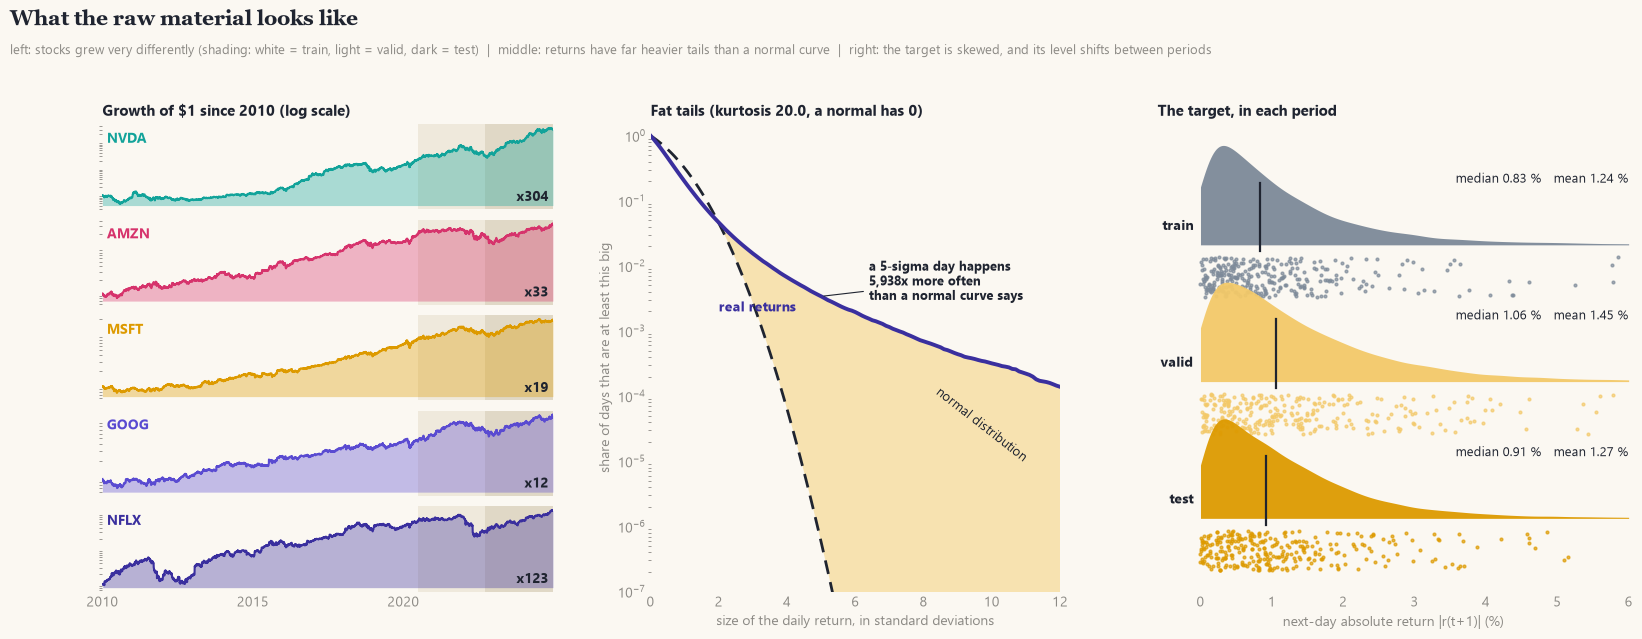

In [5]:
from scipy import stats
from scipy.stats import gaussian_kde
t_c1, t_c2, t_beg, t_end = pd.Timestamp(c1), pd.Timestamp(c2), pd.Timestamp(dates[0]), pd.Timestamp(dates[-1])
fig = plt.figure(figsize=(16.5, 6.6)); gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1, 1.15], wspace=0.22)

# A: five sparklines, one panel per stock
sub = gs[0].subgridspec(5, 1, hspace=0.12)
for i, (s, col) in enumerate(zip(TICKERS[:5], [C["rnn"], C["lstm"], C["pos"], C["neg"], "#3a2f9e"])):
    a = fig.add_subplot(sub[i]); d = px[px.Symbol == s]; g_ = (d["Adj Close"] / d["Adj Close"].iloc[0]).values
    a.axvspan(t_c1, t_c2, color="#efe9dc", lw=0); a.axvspan(t_c2, t_end, color="#e0d8c6", lw=0)
    a.fill_between(d.Date, g_, g_.min() * 0.85, color=col, alpha=0.35, lw=0); a.plot(d.Date, g_, color=col, lw=1.5)
    a.set_yscale("log"); a.set_yticks([]); a.set_xlim(t_beg, t_end); a.set_xticks([])
    a.text(0.01, 0.9, s, transform=a.transAxes, fontweight="bold", color=col, va="top")
    a.text(0.99, 0.1, f"x{g_[-1]:.0f}", transform=a.transAxes, ha="right", fontweight="bold")
    if i == 0: a.set_title("Growth of $1 since 2010 (log scale)")
a.set_xticks([pd.Timestamp(f"{y}-01-01") for y in (2010, 2015, 2020)], ["2010", "2015", "2020"])

# B: how often are big moves, compared with a normal distribution
r = px.ret.values; z = (r - r.mean()) / r.std(); xs = np.linspace(0, 12, 121)
emp = np.array([(np.abs(z) > x).mean() for x in xs]); nor = 2 * stats.norm.sf(xs); ok = emp > 0
b = fig.add_subplot(gs[1])
b.fill_between(xs[ok], emp[ok], nor[ok], where=emp[ok] > nor[ok], color=C["amb_l"], lw=0)
b.plot(xs, nor, color=C["ink"], lw=2, ls=(0, (5, 3))); b.plot(xs[ok], emp[ok], color="#3a2f9e", lw=2.8)
ratio = emp[xs.searchsorted(5)] / nor[xs.searchsorted(5)]
b.annotate(f"a 5-sigma day happens\n{ratio:,.0f}x more often\nthan a normal curve says", (5, emp[xs.searchsorted(5)]), (6.4, 3e-3), fontsize=9.5, fontweight="bold",
           arrowprops=dict(arrowstyle="-", color=C["ink"], lw=0.8))
b.text(8.3, 1e-5, "normal distribution", rotation=-38, color=C["ink"], fontsize=9.5); b.text(2.0, 2e-3, "real returns", color="#3a2f9e", fontweight="bold", fontsize=10)
b.set_yscale("log"); b.set_ylim(1e-7, 1.5); b.set_xlim(0, 12); b.set_xlabel("size of the daily return, in standard deviations"); b.set_ylabel("share of days that are at least this big")
b.set_title(f"Fat tails (kurtosis {pd.Series(r).kurt():.1f}, a normal has 0)")

# C: rainclouds of the target in the three periods
c_ = fig.add_subplot(gs[2]); tg = 100 * px.target.values; dd = px.Date.values; rng = np.random.default_rng(0); grid = np.linspace(0, 6, 300)
periods = [("train", dd < np.datetime64(t_c1), "#7d8a99"), ("valid", (dd >= np.datetime64(t_c1)) & (dd < np.datetime64(t_c2)), "#f3c969"), ("test", dd >= np.datetime64(t_c2), C["pos"])]
for i, (name, msk, col) in enumerate(periods):
    v = tg[msk]; y0 = 2.2 - 1.1 * i
    kd = gaussian_kde(rng.choice(v, 20000, replace=False), bw_method=0.12)(grid); kd = kd / kd.max() * 0.8
    c_.fill_between(grid, y0, y0 + kd, color=col, alpha=0.95, lw=0)
    sm = rng.choice(v[v < 6], 300, replace=False); c_.scatter(sm, y0 - 0.1 - rng.random(300) * 0.32, s=4, color=col, alpha=0.7)
    c_.plot([np.median(v)] * 2, [y0 - 0.05, y0 + 0.5], color=C["ink"], lw=1.6)
    c_.text(-0.1, y0 + 0.12, name, ha="right", fontweight="bold"); c_.text(6, y0 + 0.5, f"median {np.median(v):.2f} %   mean {v.mean():.2f} %", ha="right", fontsize=9)
c_.set_xlim(-0.6, 6); c_.set_yticks([]); c_.set_xlabel("next-day absolute return |r(t+1)| (%)"); c_.set_title("The target, in each period")
headline(fig, "What the raw material looks like", "left: stocks grew very differently (shading: white = train, light = valid, dark = test)  |  middle: returns have far heavier tails than a normal curve  |  right: the target is skewed, and its level shifts between periods")
finish(fig, "ST_eda", top_in=1.2)

**Reading the pictures.** On the left, the same fifteen years turn $1 into very different amounts: about $12 for GOOG but $304 for NVDA. Prices wander without a fixed level, so they are useless as network inputs (a network trained on the low prices of 2010 would see 2024 as an alien world). Returns, which are relative changes, have no such trend, which is why we use them.

The middle chart plots, for every size $x$ measured in standard deviations, the share of days on which the return was at least that large. For a normal distribution the curve (dashed) falls so fast that days beyond 5 standard deviations should practically never happen; in reality 0.34 % of all stock-days are that large, which is about 5,900 times more often. The kurtosis of 20 (a normal distribution has 0) says the same in one number. Large moves are rare but not *that* rare, and because the loss is the mean of *squared* errors, these few days weigh heavily: one 15 % day contributes as much error as a hundred 1.5 % days. This is why forecasting volatility day by day is hard, and why we should expect a low R².

The rainclouds on the right show the target in each period (the half violin is the distribution, the dots are a random sample of days, the vertical bar is the median). Two things stand out. The distribution is skewed to the right: most days are small and a few are huge, so the mean (1.24 % in the training period) lies above the median (0.83 %). And the periods differ: the validation period was clearly more turbulent (mean 1.45 %, median 1.06 %) than the training period, the test period (mean 1.27 %) roughly like the training period. A model that learned the calm training years has to forecast a stormier world in validation, which should make the validation loss of §7 look worse than the training loss even before any overfitting.

### Volatility clustering: why $\lvert r\rvert$ is predictable and $r$ is not

To measure how much a series remembers its own past we use the **autocorrelation**. The autocorrelation at lag $k$, $\rho_k=\mathrm{corr}(z_t,z_{t-k})$, is the ordinary correlation between the series and the same series shifted by $k$ days. If tomorrow's value tends to resemble today's, $\rho_1$ is positive; if there is no relationship it is close to 0. With a long series, pure noise produces values within about ±0.03 (the grey band in the chart), so anything outside that band is real memory.

We compute it twice for every stock and average over the stocks: once for the signed return $r_t$ (does a rise predict a rise?) and once for its size $\lvert r_t\rvert$ (does a big move predict a big move?). The chart also shows a calendar of the average daily move for every month, to see the clusters directly.

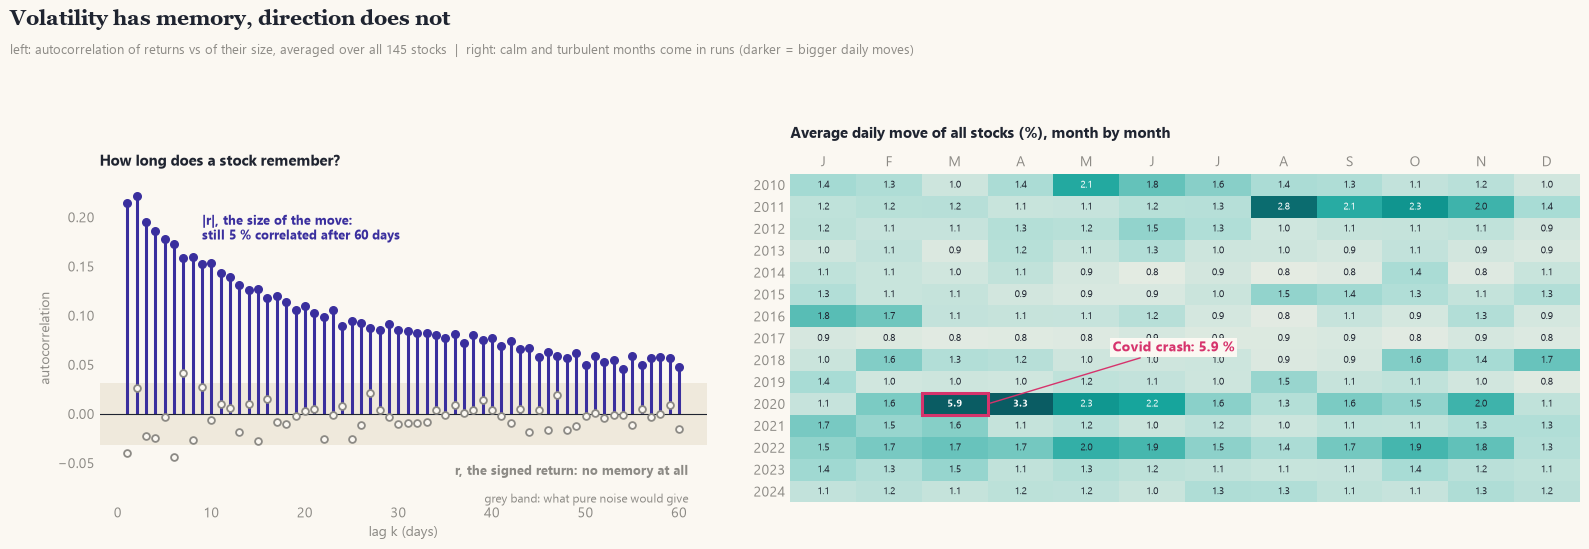

Autocorrelation at lag 1: signed return -0.040, size of the return 0.215. At lag 60 the size is still 0.048. Pure noise would stay within +-0.032.


In [6]:
def acf(x, lags):
    x = x - x.mean(); v = (x * x).mean()
    return np.array([(x[k:] * x[:-k]).mean() / v for k in lags])
lags = np.arange(1, 61)
a_r = np.mean([acf(px[px.Symbol == s].ret.values, lags) for s in TICKERS], 0)
a_abs = np.mean([acf(np.abs(px[px.Symbol == s].ret.values), lags) for s in TICKERS], 0)
band = 1.96 / np.sqrt(len(px[px.Symbol == TICKERS[0]]))               # what pure noise would produce (95 %)

fig = plt.figure(figsize=(16, 5.6)); gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.3], wspace=0.12)
a = fig.add_subplot(gs[0])
a.axhspan(-band, band, color="#efe9dc", lw=0); a.text(61, -0.081, "grey band: what pure noise would give", ha="right", va="top", fontsize=8.5, color=C["mute"]); a.set_ylim(-0.09, 1.1 * a_abs.max())
a.vlines(lags, 0, a_abs, color="#3a2f9e", lw=2.2); a.scatter(lags, a_abs, s=30, color="#3a2f9e", zorder=3)
a.scatter(lags, a_r, s=24, facecolor=C["paper"], edgecolor=C["mute"], lw=1.3, zorder=3)
a.text(9, a_abs[8] + 0.025, f"|r|, the size of the move:\nstill {100 * a_abs[-1]:.0f} % correlated after 60 days", color="#3a2f9e", fontweight="bold", fontsize=9.5)
a.text(61, -0.062, "r, the signed return: no memory at all", ha="right", color=C["mute"], fontweight="bold", fontsize=9.5)
a.axhline(0, color=C["ink"], lw=0.8); a.set_xlabel("lag k (days)"); a.set_ylabel("autocorrelation"); a.set_title("How long does a stock remember?")

b = fig.add_subplot(gs[1])
mm = px.groupby([px.Date.dt.year, px.Date.dt.month]).ret.apply(lambda s: 100 * s.abs().mean()).unstack()
vmax = 3.0
b.imshow(mm.values, cmap=SEQ, aspect="auto", vmin=0.6, vmax=vmax)
for (i, j), v in np.ndenumerate(mm.values):
    if not np.isnan(v): b.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.6 + 0.6 * (vmax - 0.6) else C["ink"], fontweight="bold" if v > 3 else "normal")
b.set_yticks(range(len(mm)), mm.index); b.set_xticks(range(12), list("JFMAMJJASOND")); b.xaxis.tick_top()
i20 = list(mm.index).index(2020); b.add_patch(Rectangle((1.5, i20 - 0.5), 1, 1, fill=False, ec=C["lstm"], lw=2.2))
b.annotate(f"Covid crash: {mm.values[i20, 2]:.1f} %", (2.5, i20), (4.4, i20 - 2.4), color=C["lstm"], fontweight="bold", bbox=dict(fc=C["paper"], ec="none", pad=2), arrowprops=dict(arrowstyle="-", color=C["lstm"], lw=1))
b.set_title("Average daily move of all stocks (%), month by month", pad=26)
headline(fig, "Volatility has memory, direction does not", f"left: autocorrelation of returns vs of their size, averaged over all {len(TICKERS)} stocks  |  right: calm and turbulent months come in runs (darker = bigger daily moves)")
finish(fig, "ST_clustering", top_in=1.7)
print("Autocorrelation at lag 1: signed return %.3f, size of the return %.3f. At lag 60 the size is still %.3f. Pure noise would stay within +-%.3f." % (a_r[0], a_abs[0], a_abs[-1], band))

**Reading the autocorrelation.** The signed return has no memory: its autocorrelation at lag 1 is $-0.040$ and stays within the noise band at every lag up to 60, so yesterday's direction says nothing reliable about tomorrow's. The size of the move is the opposite. Its autocorrelation is 0.215 at lag 1, 0.222 at lag 2, still 0.178 at five days, 0.110 at twenty days, 0.077 at forty days and 0.048 at sixty days, all clearly above the noise band. The memory of volatility is therefore long, but it fades: the correlation halves after about 20 days. That is a very useful finding for the rest of the notebook. A model has to look back a few weeks to use it (so $T=60$ is reasonable), but most of the information sits in the most recent days.

The calendar shows the same thing in a different way: the dark cells come in runs. August to November 2011 (the US credit downgrade and the euro crisis) averages 2.0–2.8 % per day, March and April 2020 (Covid) reach 5.9 % and 3.3 %, and 2022 (rapid interest-rate rises) stays between 1.3 and 2.0 % for the whole year, while the quiet years 2013, 2014 and 2017 sit at about 1 %. Volatility is something a stock *has* for a while, which is why a recurrent network that accumulates evidence over time should be able to forecast it, and why the length of its memory is what the LSTM-versus-RNN comparison is about.

## 4. Windows, scaling and baselines

**Scaling.** Features of very different size (a return of 0.02, a log volume of 20) confuse a network, so each feature is **z-scored**, $z=(x-\mu)/\sigma$: subtract the mean and divide by the standard deviation, so that every feature has mean 0 and standard deviation 1 and a value of 2 means "two standard deviations above usual". The statistics $\mu$ and $\sigma$ are computed on the **training period only**; using the validation or test period would let information from the future into the preprocessing. Log volume is standardised per stock (a company's typical trading volume is its own business), the other three features over all stocks together. The target is standardised the same way, which makes the loss easy to read: a model that always predicts the training mean has a loss of about 1.

**Windows.** For each stock the series of $F=4$ features is cut into overlapping windows. The input of one example is the features of days $t-59,\dots,t$ and the target is $\lvert r_{t+1}\rvert$. A tiny example with $T=3$: the features of days 1, 2, 3 predict $\lvert r_4\rvert$; the features of days 2, 3, 4 predict $\lvert r_5\rvert$; and so on, so each day is used in many windows. A window belongs to the training, validation or test set according to the date of its **target**, so no target ever crosses a split boundary. (A test window may look back into the validation period for its inputs, which is fine because those inputs are known at forecast time in real use.)

In [7]:
FEATS = ["ret", "hl", "oc", "lvol"]
tr_mask = px.Date < c1
lvol_mean = px[tr_mask].groupby("Symbol").lvol.mean()
lvol_std = px[tr_mask].groupby("Symbol").lvol.std()
px["lvol"] = (px.lvol - px.Symbol.map(lvol_mean)) / px.Symbol.map(lvol_std)
mu = px.loc[tr_mask, ["ret", "hl", "oc"]].mean(); sd = px.loc[tr_mask, ["ret", "hl", "oc"]].std()
for f in ["ret", "hl", "oc"]: px[f] = (px[f] - mu[f]) / sd[f]
y_mu, y_sd = px.loc[tr_mask, "target"].mean(), px.loc[tr_mask, "target"].std()

def make_windows(d):
    F = d[FEATS].values.astype("float32"); y = d.target.values.astype("float32"); dt = d.Date.values
    raw_abs = np.abs(d.ret.values * sd["ret"] + mu["ret"])                     # |r_t| in original units, for baselines
    idx = np.arange(T - 1, len(d))
    X = np.stack([F[i - T + 1:i + 1] for i in idx])
    return X, y[idx], dt[idx], raw_abs[idx], np.array([raw_abs[max(0, i - 19):i + 1].mean() for i in idx])

parts = {k: [] for k in ["X", "y", "date", "abs_now", "abs_mean20", "sym"]}
for s in TICKERS:
    X, y, dt, a_now, a_m20 = make_windows(px[px.Symbol == s])
    for k, v in zip(["X", "y", "date", "abs_now", "abs_mean20"], [X, y, dt, a_now, a_m20]): parts[k].append(v)
    parts["sym"].append(np.full(len(y), s))
A = {k: np.concatenate(v) for k, v in parts.items()}
split = np.where(A["date"] < c1, 0, np.where(A["date"] < c2, 1, 2))
ys = (A["y"] - y_mu) / y_sd                                                        # standardised target
Xtr, Xva, Xte = (A["X"][split == i] for i in range(3))
ytr, yva, yte_s = (ys[split == i] for i in range(3))
yte = A["y"][split == 2]                                                           # test target in original units
print(f"Windows: {len(Xtr):,} for training, {len(Xva):,} for validation, {len(Xte):,} for testing. Training input shape {Xtr.shape} = (windows, days, features).")

Windows: 373,665 for training, 81,925 for validation, 81,925 for testing. Training input shape (373665, 60, 4) = (windows, days, features).


**What the windows look like.** The 145 stocks produce 373,665 training windows, 81,925 validation windows and 81,925 test windows, each a table of 60 days × 4 features. Overlapping windows from the same stock are strongly related (two neighbouring windows share 59 of their 60 days), so the 373,665 examples carry less independent information than their number suggests; this is another reason why overfitting happens quickly in §7.

### What one training example looks like

One window is a $60\times4$ table of z-scores and one number to predict. On the left it is drawn as a barcode (each column is a day, each row a feature, colour is the z-score: magenta high, indigo low); the amber tile is the number the network must predict. The bubble matrix on the right shows how the features and the target relate to each other on the training period, which tells us what signal the network can use.

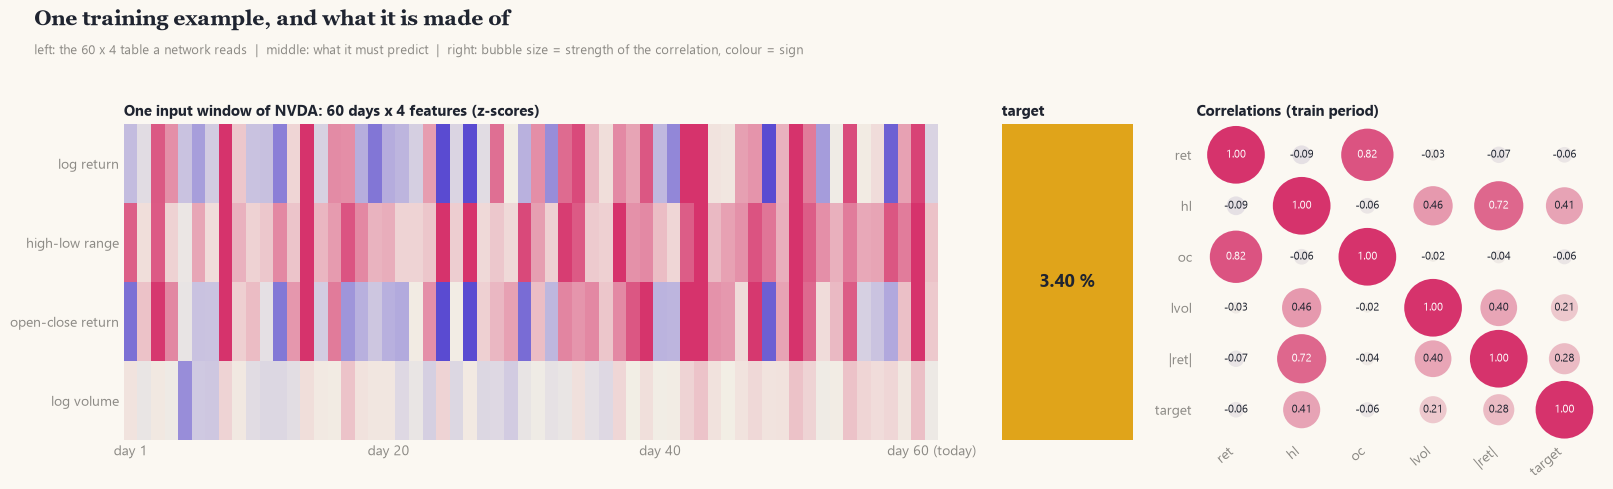

In [8]:
j = np.where((A["sym"] == TICKERS[0]) & (split == 2))[0][100]
win, tgt_j = A["X"][j], 100 * A["y"][j]
names = ["log return", "high-low range", "open-close return", "log volume"]
fig = plt.figure(figsize=(16, 4.9)); gs = fig.add_gridspec(1, 3, width_ratios=[3.4, 0.55, 1.7], wspace=0.14)
a = fig.add_subplot(gs[0]); a.imshow(win.T, cmap=DIV, vmin=-3, vmax=3, aspect="auto", interpolation="nearest")
a.set_yticks(range(4), names); a.set_xticks([0, 19, 39, 59], ["day 1", "day 20", "day 40", "day 60 (today)"]); a.set_title(f"One input window of {TICKERS[0]}: {T} days x {len(FEATS)} features (z-scores)")
t = fig.add_subplot(gs[1]); t.imshow([[tgt_j]], cmap=LinearSegmentedColormap.from_list("t", [C["amb_l"], C["pos"]]), vmin=0, vmax=4, aspect="auto")
t.text(0, 0, f"{tgt_j:.2f} %", ha="center", va="center", fontsize=13, fontweight="bold"); t.set_xticks([]); t.set_yticks([]); t.set_title("target")
tab = pd.concat([px.loc[tr_mask, FEATS], px.loc[tr_mask, "ret"].abs().rename("|ret|"), px.loc[tr_mask, "target"].rename("target")], axis=1).corr()
c = fig.add_subplot(gs[2]); n = len(tab)
for (i, jj), v in np.ndenumerate(tab.values):
    c.scatter(jj, i, s=1700 * abs(v) + 25, color=DIV((v + 1) / 2), edgecolor="none"); c.text(jj, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else C["ink"])
c.set_xlim(-0.6, n - 0.4); c.set_ylim(n - 0.4, -0.6); c.set_xticks(range(n), tab.columns, rotation=40, ha="right"); c.set_yticks(range(n), tab.columns); c.set_title("Correlations (train period)")
headline(fig, "One training example, and what it is made of", "left: the 60 x 4 table a network reads  |  middle: what it must predict  |  right: bubble size = strength of the correlation, colour = sign")
finish(fig, "ST_windows", top_in=1.2)

**Reading the bubble matrix.** The target is clearly related to the *range and volume* features and not to the signed ones. The high–low range has a correlation of 0.41 with tomorrow's move, the absolute return of today 0.28 and the log volume 0.21, while the signed log return and the open–close return have correlations of −0.06, that is, nothing. Two features are almost the same thing: the log return and the open–close return correlate at 0.82, so one of them is partly redundant, and the high–low range correlates at 0.72 with the size of today's return. All of this fits the clustering picture: how wild today was (range, volume, absolute return) is informative about tomorrow, which way the price went is not. A correlation of 0.41 means that this single feature explains about 17 % of the variance of tomorrow's move (0.41² = 0.17), a number to keep in mind when we judge the R² of the networks.

### Metrics and baselines

All errors are reported in the original unit, the absolute daily log return, shown in percent. Four numbers describe a forecast $\hat y$ against the truth $y$ over $N$ test windows:

- **RMSE** $=\sqrt{\frac1N\sum(y-\hat y)^2}$, the typical size of a miss with big misses weighted more; **MAE** $=\frac1N\sum\lvert y-\hat y\rvert$, the plain average miss. If a model predicts 1 % and the truth is 3 % the miss is 2 points.
- **Out-of-sample $R^2$** $=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y_{\text{train}})^2}$: the share of the squared error that the model removes compared with always predicting the training average. $R^2=0$ means no better than that constant, $R^2=1$ would be perfect, and a negative value means worse than the constant. For daily volatility forecasts, values of a few percent to ten percent are normal, because day-to-day noise is huge.
- **Correlation** between forecast and truth, which ignores any constant offset or scale and asks only whether the forecast rises and falls with the truth.

Three baselines a model must beat:

- **train mean**: always predict the average $\lvert r\rvert$ of the training period (the "know nothing" forecast, $R^2=0$ by construction);
- **persistence**: tomorrow's move equals today's move, $\hat y=\lvert r_t\rvert$ (the "use only the last day" forecast);
- **20-day mean**: the average $\lvert r\rvert$ of the last 20 days, a classical volatility estimator that uses a bit of memory without any learning.

In [9]:
RUNS = {}
def metrics(y, p):
    e = y - p
    return dict(rmse=float(np.sqrt((e ** 2).mean())), mae=float(np.abs(e).mean()),
                r2_oos=float(1 - (e ** 2).sum() / ((y - y_mu) ** 2).sum()), corr=float(np.corrcoef(y, p)[0, 1]))
BASE = {"train mean": metrics(yte, np.full_like(yte, y_mu)),
        "persistence |r_t|": metrics(yte, A["abs_now"][split == 2]),
        "20-day mean |r|": metrics(yte, A["abs_mean20"][split == 2])}
display((pd.DataFrame(BASE).T * [100, 100, 1, 1]).rename(columns={"rmse": "RMSE (%)", "mae": "MAE (%)"}).round(4))

def finalize(run_id, p_std, history, params, sec_epoch, total_s):
    p = p_std * y_sd + y_mu                                                  # back to original units
    rec = dict(run_id=run_id, params=int(params), sec_per_epoch=round(sec_epoch, 2), train_seconds=round(total_s, 1),
               epochs=len(history["loss"]), best_epoch=int(np.argmin(history["val_loss"]) + 1), history=history, **metrics(yte, p))
    RUNS[run_id] = {**rec, "pred": p}
    json.dump(rec, open(RES / f"{run_id}.json", "w"), indent=1)
    print(f"{run_id} finished: RMSE {100 * rec['rmse']:.4f} %, MAE {100 * rec['mae']:.4f} %, R2 {rec['r2_oos']:.4f}, correlation {rec['corr']:.3f}. "
          f"It trained for {rec['epochs']} epochs (best epoch: {rec['best_epoch']}) at {sec_epoch:.0f} s per epoch.")

def rnn_params(F, H, L, nb=1):  return F * H + H * H + nb * H + (L - 1) * (2 * H * H + nb * H)
EXPECTED = {"RNN": rnn_params(4, H, LAYERS) + H + 1, "LSTM": 4 * rnn_params(4, H, LAYERS) + H + 1}
print("Parameter counts we expect (Keras counting, one bias vector per layer):", EXPECTED)

,RMSE (%),MAE (%),r2_oos,corr
train mean,1.3632,0.8809,-0.0000,NaN
persistence |r_t|,1.7783,1.1281,-0.7018,0.1492
20-day mean |r|,1.3326,0.8656,0.0443,0.2510


Parameter counts we expect (Keras counting, one bias vector per layer): {'RNN': 9537, 'LSTM': 38049}


**Reading the baselines.** Persistence is *worse* than the training mean (R² of −0.70, RMSE 1.78 % against 1.36 %): one day's move is a noisy estimate of tomorrow's, because a single large or small move is partly luck. Averaging 20 days removes much of that noise and beats the mean (RMSE 1.33 %, R² 0.044, correlation 0.25). That is the volatility clustering of §3 put to work with no learning at all. The recurrent networks have to beat the 20-day mean to show that they have learned something more than a moving average.

## 5. Keras — runs `ST-TF-RNN`, `ST-TF-LSTM`

The network is `Input((60, 4))`, four recurrent layers that return their whole sequence of states, a fifth that returns only its last state, and `Dense(1)` with no activation, because the output is a real number that may take any value (a sigmoid would cap it between 0 and 1, and the standardised target can be negative). The parameter count follows the formula of the concepts notebook. For the RNN: the first layer has $4\cdot32+32\cdot32+32=1{,}184$ numbers, layers 2–5 have $2\cdot32^2+32=2{,}080$ each, the output layer 33, together $9{,}537$. The LSTM has four times as many numbers in the recurrent layers, $38{,}049$ in total, because each of its four gates is an RNN-sized block. In contrast to the reviews there is no embedding to dominate the count, so here the LSTM really is four times larger.

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)
print(f"Using TensorFlow {tf.__version__}; GPUs found: {len(tf.config.list_physical_devices('GPU'))} (0 means everything runs on the CPU).")

def build_keras(kind):
    cell = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM}[kind]
    m = keras.Sequential([layers.Input((T, len(FEATS)))] + [cell(H, return_sequences=(l < LAYERS - 1)) for l in range(LAYERS)] + [layers.Dense(1)],
                         name=f"keras_{kind}")
    m.compile(optimizer=keras.optimizers.Adam(LR, clipnorm=CLIP), loss="mse")
    return m

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self.t)

def run_keras(kind):
    tf.keras.utils.set_random_seed(SEED)
    m = build_keras(kind); assert m.count_params() == EXPECTED[kind], (m.count_params(), EXPECTED[kind])
    timer = EpochTimer(); t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH, verbose=2,
              callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True), timer])
    p = m.predict(Xte, batch_size=2048, verbose=0)[:, 0]
    finalize(f"ST-TF-{kind}", p, {"loss": h.history["loss"], "val_loss": h.history["val_loss"]}, m.count_params(),
             float(np.median(timer.times[1:] or timer.times)), time.time() - t0)

build_keras("LSTM").summary()

Using TensorFlow 2.22.0-rc0; GPUs found: 0 (0 means everything runs on the CPU).


Model: "keras_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 32)         │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 60, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 60, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,049 (148.63 KB)

 Trainable params: 38,049 (148.63 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
run_keras("RNN")

Epoch 1/10


1460/1460 - 54s - 37ms/step - loss: 0.7851 - val_loss: 0.8749


Epoch 2/10


1460/1460 - 52s - 36ms/step - loss: 0.7555 - val_loss: 0.8831


Epoch 3/10


1460/1460 - 50s - 35ms/step - loss: 0.7460 - val_loss: 0.8768


ST-TF-RNN finished: RMSE 1.3015 %, MAE 0.8419 %, R2 0.0884, correlation 0.300. It trained for 3 epochs (best epoch: 1) at 51 s per epoch.


In [12]:
run_keras("LSTM")

Epoch 1/10


1460/1460 - 144s - 99ms/step - loss: 0.7832 - val_loss: 0.8805


Epoch 2/10


1460/1460 - 139s - 95ms/step - loss: 0.7487 - val_loss: 0.8749


Epoch 3/10


...

Epoch 5/10


1460/1460 - 136s - 93ms/step - loss: 0.7253 - val_loss: 0.8745


Epoch 6/10


1460/1460 - 140s - 96ms/step - loss: 0.7172 - val_loss: 0.8739


ST-TF-LSTM finished: RMSE 1.2990 %, MAE 0.8158 %, R2 0.0920, correlation 0.311. It trained for 6 epochs (best epoch: 4) at 138 s per epoch.


**Reading the Keras runs.** The learning curves are flat. The RNN's best validation loss is already reached in epoch 1 (0.875) and gets worse afterwards (0.883, 0.877); the LSTM improves slowly until epoch 4 (0.873) and then stays level. In both cases the training loss keeps falling (the RNN from 0.785 to 0.746, the LSTM from 0.783 to 0.717), so the networks start to fit the particular training windows rather early. Early stopping stops the RNN after 3 epochs and the LSTM after 6. On the test windows the RNN reaches an RMSE of 1.3015 % and an R² of 0.088, the LSTM 1.2990 % and 0.092: nearly the same. The cost is not the same: 51 seconds per epoch against 138, because the LSTM computes four gates per step.

## 6. PyTorch — runs `ST-PT-RNN`, `ST-PT-LSTM`

The PyTorch model is `nn.RNN(4, 32, num_layers=5, batch_first=True)` (or `nn.LSTM`), then the last step of the top layer, then `nn.Linear(32, 1)`, with a hand-written training loop (batch, forward pass, loss, backward pass, clipping, optimizer step, validation, early stopping). As in the review notebook, the weights are initialised exactly like Keras's (Glorot-uniform input weights, orthogonal recurrent weights, zero biases, LSTM forget-gate bias 1) so that both libraries start from the same kind of point. PyTorch's second bias vector per layer adds $5\cdot32=160$ numbers to the RNN and $5\cdot128=640$ to the LSTM, all starting at zero; the function computed is the same.

In [13]:
import torch, torch.nn as nn
torch.manual_seed(SEED)
DEV = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Using PyTorch {torch.__version__} on the {DEV.type.upper()}.")

class TorchVol(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM}[kind](len(FEATS), H, num_layers=LAYERS, batch_first=True)
        self.head = nn.Linear(H, 1)
        for name, p in self.rnn.named_parameters():
            if name.startswith("weight_ih"):
                for blk in p.data.chunk(4 if kind == "LSTM" else 1): nn.init.xavier_uniform_(blk)
            elif name.startswith("weight_hh"):
                for blk in p.data.chunk(4 if kind == "LSTM" else 1): nn.init.orthogonal_(blk)
            else:
                nn.init.zeros_(p)
                if kind == "LSTM" and name.startswith("bias_ih"): p.data[H:2 * H] = 1.0
        nn.init.xavier_uniform_(self.head.weight); nn.init.zeros_(self.head.bias)
    def forward(self, x):                    # x: (B, 60, 4)
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(1)

def predict_torch(m, X, bs=4096):
    m.eval()
    with torch.no_grad():
        return np.concatenate([m(torch.from_numpy(X[i:i + bs]).to(DEV)).cpu().numpy() for i in range(0, len(X), bs)])

def run_torch(kind):
    torch.manual_seed(SEED)
    m = TorchVol(kind).to(DEV); n = sum(p.numel() for p in m.parameters())
    assert n == EXPECTED[kind] + LAYERS * H * (4 if kind == "LSTM" else 1)
    opt = torch.optim.Adam(m.parameters(), lr=LR, eps=1e-7); lossf = nn.MSELoss()
    Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr)
    hist = {"loss": [], "val_loss": []}; times = []; best, best_state, wait = np.inf, {k: v.detach().clone() for k, v in m.state_dict().items()}, 0
    g = torch.Generator().manual_seed(SEED); t0 = time.time()
    for ep in range(EPOCHS):
        m.train(); te = time.time(); tot = 0.0
        for b in torch.randperm(len(Xt), generator=g).split(BATCH):
            xb, yb = Xt[b].to(DEV), yt[b].to(DEV)
            loss = lossf(m(xb), yb)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), CLIP); opt.step()
            tot += loss.item() * len(b)
        vl = float(((predict_torch(m, Xva) - yva) ** 2).mean()); times.append(time.time() - te)
        hist["loss"].append(tot / len(Xt)); hist["val_loss"].append(vl)
        print(f"epoch {ep + 1}: training loss {hist['loss'][-1]:.4f}, validation loss {vl:.4f} ({times[-1]:.0f} s)")
        if vl < best - 1e-4:
            best, wait = vl, 0; best_state = {k: v.detach().clone() for k, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE: break
    m.load_state_dict(best_state)
    finalize(f"ST-PT-{kind}", predict_torch(m, Xte), hist, n, float(np.median(times[1:] or times)), time.time() - t0)

print(TorchVol("RNN"))

Using PyTorch 2.14.1+cpu on the CPU.
TorchVol(
  (rnn): RNN(4, 32, num_layers=5, batch_first=True)
  (head): Linear(in_features=32, out_features=1, bias=True)
)


In [14]:
run_torch("RNN")

epoch 1: training loss 0.7926, validation loss 0.8771 (44 s)


epoch 2: training loss 0.7583, validation loss 0.8710 (46 s)


epoch 3: training loss 0.7423, validation loss 0.8984 (46 s)


epoch 4: training loss 0.7336, validation loss 0.8997 (45 s)


ST-PT-RNN finished: RMSE 1.3025 %, MAE 0.8238 %, R2 0.0871, correlation 0.299. It trained for 4 epochs (best epoch: 2) at 46 s per epoch.


In [15]:
run_torch("LSTM")

epoch 1: training loss 0.7856, validation loss 0.8692 (71 s)


epoch 2: training loss 0.7487, validation loss 0.8720 (69 s)


epoch 3: training loss 0.7403, validation loss 0.8635 (70 s)


epoch 4: training loss 0.7335, validation loss 0.8652 (70 s)


epoch 5: training loss 0.7268, validation loss 0.8684 (68 s)


ST-PT-LSTM finished: RMSE 1.2957 %, MAE 0.8399 %, R2 0.0965, correlation 0.311. It trained for 5 epochs (best epoch: 3) at 70 s per epoch.


**Reading the PyTorch runs.** The same picture again. The RNN reaches its lowest validation loss in epoch 2 (0.871) and then gets worse (0.898, 0.900); the LSTM's best epoch is 3 (0.864) and its validation loss moves only within 0.01 afterwards. The test results are RMSE 1.3025 % (R² 0.087) for the RNN and 1.2957 % (R² 0.097) for the LSTM, again very close and again with the LSTM slightly ahead. An epoch takes 46 seconds for the RNN and 70 for the LSTM, a smaller time ratio (1.5) than in Keras (2.7).

## 7. Comparison

Four networks and three baselines on the same 81,925 test windows (the last two and a quarter years, which no model saw while training or while choosing the best epoch). We compare the numbers, look at the learning curves, look at the forecasts themselves and finally ask where, in calm or turbulent markets, the networks help.

In [16]:
rows = [{"run": k, **{m: v[m] for m in ["rmse", "mae", "r2_oos", "corr", "params", "sec_per_epoch", "epochs", "best_epoch"]}} for k, v in RUNS.items()]
rows += [{"run": f"baseline: {k}", **v} for k, v in BASE.items()]
table = pd.DataFrame(rows).set_index("run")
table[["rmse", "mae"]] *= 100
table = table.rename(columns={"rmse": "RMSE (%)", "mae": "MAE (%)"})
table.to_csv(RES / "ST_comparison.csv")
display(table.round(4))

,RMSE (%),MAE (%),r2_oos,corr,params,sec_per_epoch,epochs,best_epoch
run,,,,,,,,
ST-TF-RNN,1.3015,0.8419,0.0884,0.2995,9537.0,51.15,3.0,1.0
ST-TF-LSTM,1.2990,0.8158,0.0920,0.3114,38049.0,138.26,6.0,4.0
ST-PT-RNN,1.3025,0.8238,0.0871,0.2992,9697.0,45.58,4.0,2.0
ST-PT-LSTM,1.2957,0.8399,0.0965,0.3107,38689.0,69.61,5.0,3.0
baseline: train mean,1.3632,0.8809,-0.0000,NaN,NaN,NaN,NaN,NaN
baseline: persistence |r_t|,1.7783,1.1281,-0.7018,0.1492,NaN,NaN,NaN,NaN
baseline: 20-day mean |r|,1.3326,0.8656,0.0443,0.2510,NaN,NaN,NaN,NaN


**Reading the table.** All four networks beat all three baselines on every metric: the RMSE falls from 1.3326 % (20-day mean) to between 1.2957 % and 1.3025 %, and the R² roughly doubles, from 0.044 to between 0.087 and 0.097. So the networks learned something real that goes beyond a moving average: they weigh the recent days adaptively and use the range and volume features. In absolute terms, however, the gain is small: they explain about 9 % of the squared error of tomorrow's move, which is the typical size for this problem.

The LSTM is slightly ahead of the RNN on RMSE, R² and correlation in both libraries (R² 0.092 against 0.088 in Keras, 0.097 against 0.087 in PyTorch; correlation 0.311 against 0.300 and 0.311 against 0.299), but the differences, between 0.002 and 0.007 percentage points of RMSE, are within the noise of a single run, and on MAE the order is not even consistent (the Keras LSTM is better, the PyTorch LSTM slightly worse). Meanwhile the LSTM has four times the parameters (38,049 against 9,537) and needs 1.5 to 2.7 times as long per epoch. On this task the LSTM's extra memory buys very little.

### Scoreboard

The same numbers as a radar chart: each of the four axes (RMSE, MAE, R² and correlation) is stretched so that the best entry reaches the rim and the worst sits near the centre, with RMSE and MAE inverted so that a larger shape always means a better forecast. The table next to it gives the exact values. Persistence is left out of the radar because it is so much worse that it would squash all other shapes into a speck; it is in the table.

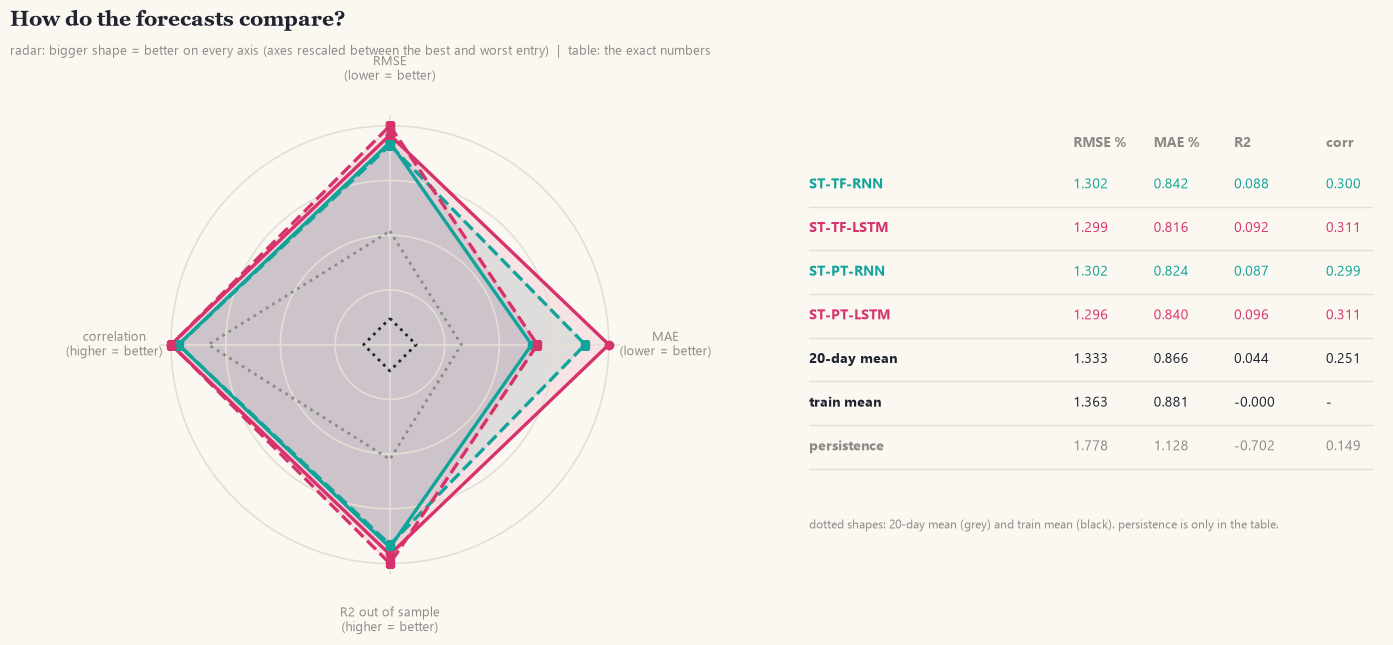

In [17]:
entries = [(k, RUNS[k]) for k in RUNS] + [("20-day mean", BASE["20-day mean |r|"]), ("train mean", BASE["train mean"])]
axes_def = [("rmse", -1, "RMSE\n(lower = better)"), ("mae", -1, "MAE\n(lower = better)"), ("r2_oos", 1, "R2 out of sample\n(higher = better)"), ("corr", 1, "correlation\n(higher = better)")]
V = np.array([[np.nan_to_num(v[m], nan=0.0) * sgn for m, sgn, _ in axes_def] for _, v in entries]); lo_, hi_ = V.min(0), V.max(0); Z = 0.12 + 0.88 * (V - lo_) / (hi_ - lo_)
ang = np.linspace(0, 2 * np.pi, len(axes_def), endpoint=False)
fig = plt.figure(figsize=(14, 6.4)); gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1])
ax = fig.add_subplot(gs[0], projection="polar"); ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1)
ax.tick_params(axis="x", pad=26); ax.set_xticks(ang, [lbl for *_, lbl in axes_def], fontsize=9.5); ax.set_yticks([0.25, 0.5, 0.75, 1.0], []); ax.set_ylim(0, 1.05)
ax.grid(color=C["rule"], lw=1.2); ax.spines["polar"].set_visible(False)
for (k, _), z in zip(entries, Z):
    zz = np.r_[z, z[0]]; aa = np.r_[ang, ang[0]]
    if k in RUNS:
        ax.fill(aa, zz, color=style(k)["color"], alpha=0.10); ax.plot(aa, zz, color=style(k)["color"], ls=style(k)["ls"], lw=2.4, marker=mk(k), ms=6)
    else:
        ax.plot(aa, zz, color=C["mute"] if k == "20-day mean" else C["ink"], ls=":", lw=2, label=k)
tb = fig.add_subplot(gs[1]); tb.axis("off"); tb.set_xlim(0, 1); tb.set_ylim(0, 1)
cols_x = [0.0, 0.46, 0.60, 0.74, 0.90]
for x_, h_ in zip(cols_x, ["", "RMSE %", "MAE %", "R2", "corr"]): tb.text(x_, 0.93, h_, fontweight="bold", color=C["mute"])
for i, (k, v) in enumerate(entries + [("persistence", BASE["persistence |r_t|"])]):
    y = 0.84 - 0.095 * i; col = style(k)["color"] if k in RUNS else (C["ink"] if k != "persistence" else C["mute"])
    tb.text(cols_x[0], y, k, color=col, fontweight="bold"); tb.plot([0, 0.98], [y - 0.04] * 2, color=C["rule"], lw=1)
    for x_, val in zip(cols_x[1:], [100 * v["rmse"], 100 * v["mae"], v["r2_oos"], v["corr"]]): tb.text(x_, y, "-" if np.isnan(val) else f"{val:.3f}", color=col)
tb.text(0, 0.1, "dotted shapes: 20-day mean (grey) and train mean (black). persistence is only in the table.", fontsize=8.5, color=C["mute"])
headline(fig, "How do the forecasts compare?", "radar: bigger shape = better on every axis (axes rescaled between the best and worst entry)  |  table: the exact numbers")
finish(fig, "ST_scores")

**Reading the radar.** The four network shapes lie almost on top of each other and clearly outside the two baseline shapes. The LSTM runs (magenta) stick out a little at the R² and correlation axes, while on the MAE axis the order is mixed: the Keras LSTM is the best and the Keras RNN the worst of the four, and the PyTorch LSTM is not better than the PyTorch RNN. The picture says in one glance what the numbers say: *recurrent versus not recurrent* matters, *RNN versus LSTM* barely does.

### Learning curves

Each cluster is one run with one dumbbell per epoch: the hollow dot is the loss on the training windows, the filled dot the loss on the validation windows, and the ring marks the epoch that early stopping kept. The dotted line is what the validation loss would be if we always predicted the training mean, so every filled dot below that line is a model that beats "no knowledge".

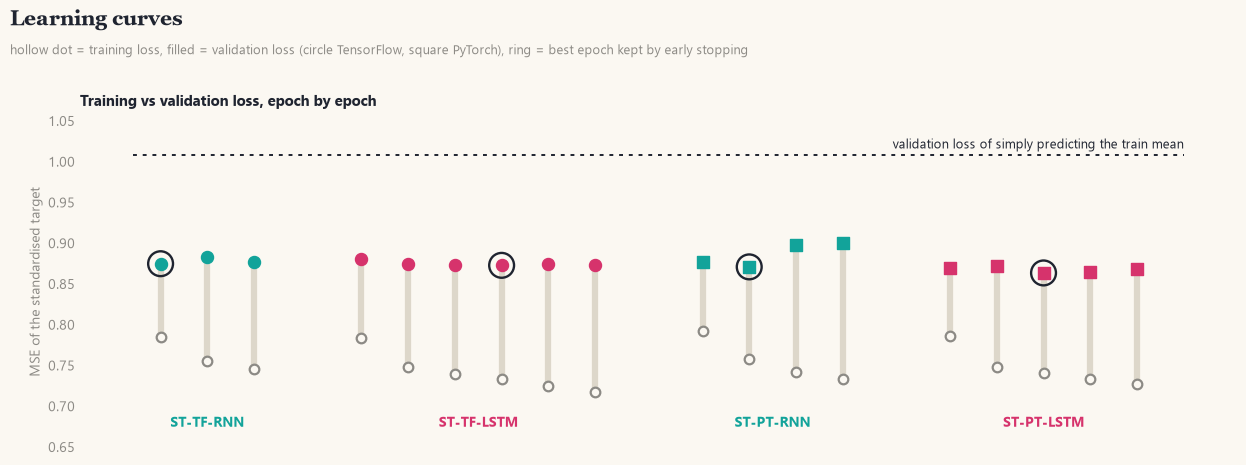

In [18]:
mean_val = float((yva ** 2).mean())                                   # validation loss of "always predict the train mean"
fig, a = plt.subplots(figsize=(12.5, 5)); x0 = 0.0
ylo = min(min(v["history"]["loss"]) for v in RUNS.values()) - 0.02
for k, v in RUNS.items():
    h = v["history"]; n = len(h["loss"]); col = style(k)["color"]
    for e in range(n):
        x = x0 + e
        a.plot([x, x], [h["loss"][e], h["val_loss"][e]], color=C["faint"], lw=4.5, solid_capstyle="round", zorder=1)
        a.scatter(x, h["loss"][e], s=48, facecolor=C["paper"], edgecolor=C["mute"], lw=1.6, zorder=3)
        a.scatter(x, h["val_loss"][e], s=75, color=col, marker=mk(k), zorder=4)
    b = v["best_epoch"] - 1
    a.scatter(x0 + b, h["val_loss"][b], s=320, facecolor="none", edgecolor=C["ink"], lw=1.7, zorder=5)
    a.text(x0 + (n - 1) / 2, ylo - 0.01, k, ha="center", va="top", color=col, fontweight="bold")
    x0 += n + 1.3
a.plot([-0.6, x0 - 1.3], [mean_val] * 2, color=C["ink"], ls=(0, (2, 3)), lw=1.4); a.text(x0 - 1.3, mean_val + 0.008, "validation loss of simply predicting the train mean", ha="right", fontsize=9)
a.set_xticks([]); a.set_ylim(ylo - 0.05, mean_val + 0.05); a.set_ylabel("MSE of the standardised target"); a.set_title("Training vs validation loss, epoch by epoch")
headline(fig, "Learning curves", "hollow dot = training loss, filled = validation loss (circle TensorFlow, square PyTorch), ring = best epoch kept by early stopping")
finish(fig, "ST_curves")

**Reading the learning curves.** Two observations. First, every validation loss (0.86 to 0.90) is far below the dotted line (1.008), so the networks beat the constant forecast on the validation period too. Second, the validation loss is higher than the training loss from the first epoch on, and the gap widens only slowly (from about 0.09 in the first epoch to 0.13–0.16 at the end): this is not only classic overfitting, it is also the **regime shift** of §3. The validation period (mid-2020 to autumn 2022) was more turbulent than the training period, so the same model makes larger errors there. Which epoch is "best" is therefore decided by small wobbles of 0.01 (best epochs 1, 4, 2 and 3), and a different seed could well choose another epoch. We keep this in mind and avoid interpreting differences between the models that are smaller than such wobbles.

### Forecast against truth

The top chart shows the first stock (NVDA) over the last 250 test days: the true size of the next day's move (amber), the 20-day-mean baseline (dotted) and the Keras RNN and LSTM forecasts, all smoothed with a 10-day average so that the lines are readable (individual days are far too noisy to draw). A volatility forecast cannot say *which* day will have a big move; a good one rises and falls with the general turbulence level. The two hexagon charts below use all 81,925 test windows: each plots the forecast against what actually happened, darker hexagons meaning more windows, and the coloured line is the average outcome for each tenth of the forecasts. If the forecasts were perfectly calibrated, the line would lie on the dashed diagonal.

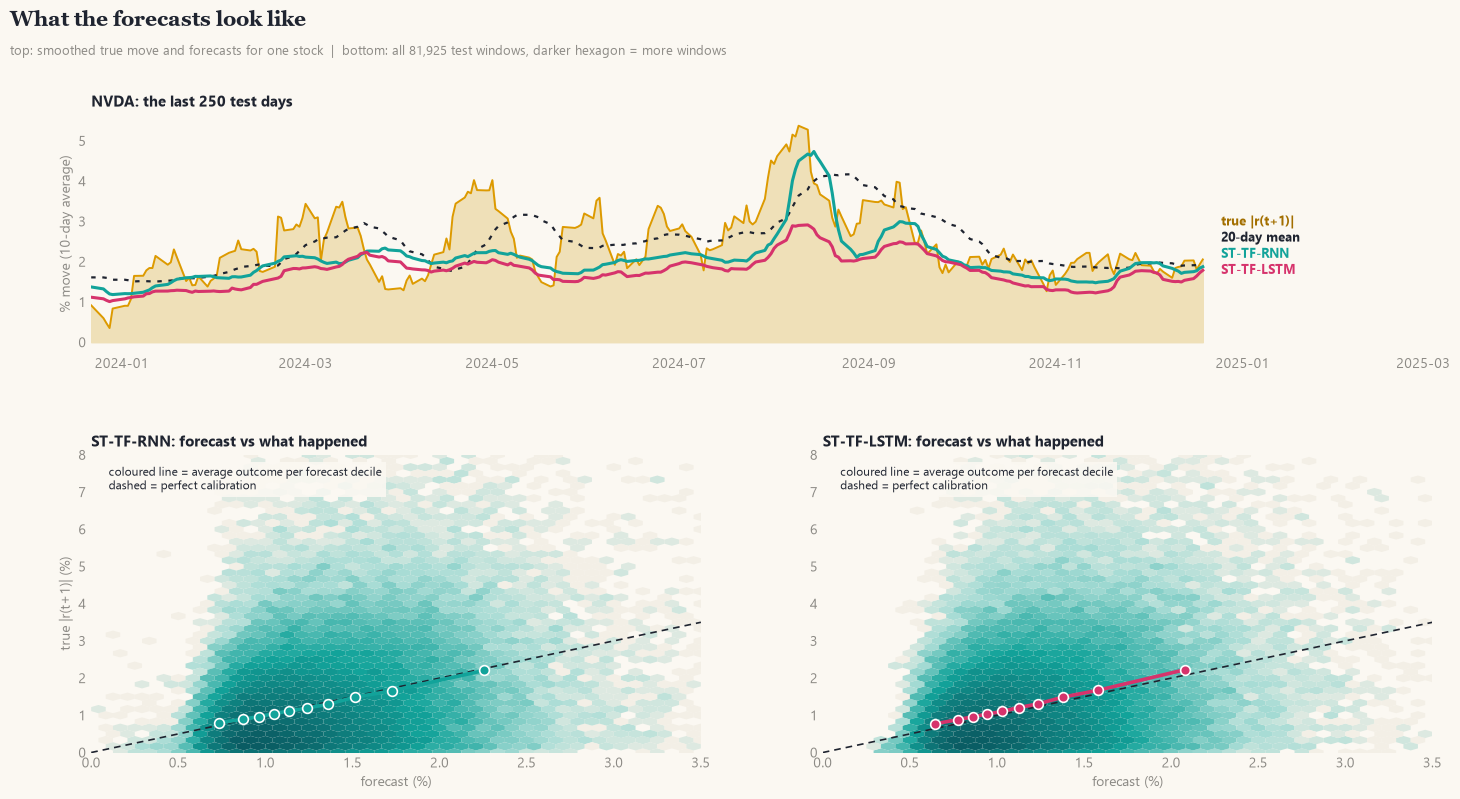

In [19]:
s0 = TICKERS[0]; m_test = split == 2; mask = A["sym"][m_test] == s0
dt = A["date"][m_test][mask][-250:]
roll = lambda v: pd.Series(v).rolling(10, min_periods=1).mean().values            # 10-day average, only to make the picture readable
fig = plt.figure(figsize=(14.5, 8.4)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], hspace=0.38)
a = fig.add_subplot(gs[0, :])
a.fill_between(dt, roll(100 * yte[mask][-250:]), color="#efe0b8"); a.plot(dt, roll(100 * yte[mask][-250:]), color=C["pos"], lw=1.4)
a.plot(dt, roll(100 * A["abs_mean20"][m_test][mask][-250:]), color=C["ink"], lw=1.6, ls=(0, (2, 3)))
for k in ["ST-TF-RNN", "ST-TF-LSTM"]:
    a.plot(dt, roll(100 * RUNS[k]["pred"][mask][-250:]), lw=2.2, color=style(k)["color"])
xe = dt[-1] + np.timedelta64(6, "D")
labels_ = sorted([("true |r(t+1)|", roll(100 * yte[mask][-250:])[-1], "#a36f00"), ("20-day mean", roll(100 * A["abs_mean20"][m_test][mask][-250:])[-1], C["ink"]),
                  ("ST-TF-RNN", roll(100 * RUNS["ST-TF-RNN"]["pred"][mask][-250:])[-1], C["rnn"]), ("ST-TF-LSTM", roll(100 * RUNS["ST-TF-LSTM"]["pred"][mask][-250:])[-1], C["lstm"])], key=lambda q: q[1])
ypos_ = []
for _, val, _ in labels_: ypos_.append(val if not ypos_ else max(val, ypos_[-1] + 0.4))        # keep the direct labels from overlapping
for (txt, val, col), yv in zip(labels_, ypos_):
    a.text(xe, yv, txt, color=col, va="center", fontweight="bold", fontsize=9.5)
a.set_xlim(dt[0], dt[-1] + np.timedelta64(75, "D")); a.set_ylabel("% move (10-day average)"); a.set_title(f"{s0}: the last 250 test days")
true_all = 100 * yte
for j, k in enumerate(["ST-TF-RNN", "ST-TF-LSTM"]):
    h = fig.add_subplot(gs[1, j]); pred = 100 * RUNS[k]["pred"]
    hb = h.hexbin(pred, true_all, gridsize=42, extent=(0, 3.5, 0, 8), bins="log", cmap=SEQ, mincnt=1, linewidths=0)
    g = pd.DataFrame({"p": pred, "y": true_all}).groupby(pd.qcut(pred, 10, labels=False, duplicates="drop")).mean()
    h.plot([0, 3.5], [0, 3.5], color=C["ink"], lw=1.2, ls=(0, (4, 3))); h.plot(g.p, g.y, color=style(k)["color"], lw=2.6, marker=mk(k), ms=7, mec="white", mew=1.2)
    h.set_xlim(0, 3.5); h.set_ylim(0, 8); h.set_xlabel("forecast (%)"); h.set_title(f"{k}: forecast vs what happened")
    if j == 0: h.set_ylabel("true |r(t+1)| (%)")
    h.text(0.1, 7.7, "coloured line = average outcome per forecast decile\ndashed = perfect calibration", ha="left", va="top", fontsize=8.5, color=C["ink"], bbox=dict(fc=C["paper"], ec="none", pad=3, alpha=0.9))
headline(fig, "What the forecasts look like", f"top: smoothed true move and forecasts for one stock  |  bottom: all {len(yte):,} test windows, darker hexagon = more windows")
finish(fig, "ST_forecast")

**Reading the forecasts.** With an R² of about 0.09 a forecast cannot follow the truth closely, and the picture reflects that: the forecast lines are much flatter than the true moves, because the networks, trained to minimise squared error on a very noisy target, hedge toward the middle. The hexagon plots show the same thing in all windows: whatever the forecast, the realised moves spread widely (a forecast of 1.5 % is followed by anything from almost nothing to several percent), but the coloured line rises with the forecast, meaning that days with a higher forecast really are, on average, more turbulent. That monotone relationship is the useful content of the forecast: it ranks days by expected turbulence, it does not predict the size of any single day.

### Error in calm and turbulent periods

The test windows are sorted into five equally large groups by the 20-day volatility level at the time of the forecast (calmest to most turbulent). If memory is what matters, the groups are where it should show: in a stable market everyone forecasts "about the same as lately", while after a regime change a model with a longer memory or better features could do better. The upper table gives the RMSE of each model in each group, the lower table how many percent of the 20-day mean's error the network removes.

,ST-TF-RNN,ST-TF-LSTM,ST-PT-RNN,ST-PT-LSTM,20-day mean
calmest,0.9813,0.9829,0.9839,0.9810,1.0108
calm,1.0622,1.0596,1.0633,1.0617,1.0791
middle,1.2380,1.2354,1.2389,1.2326,1.2525
turbulent,1.3154,1.3123,1.3168,1.3098,1.3395
most turbulent,1.7650,1.7605,1.7648,1.7522,1.8248


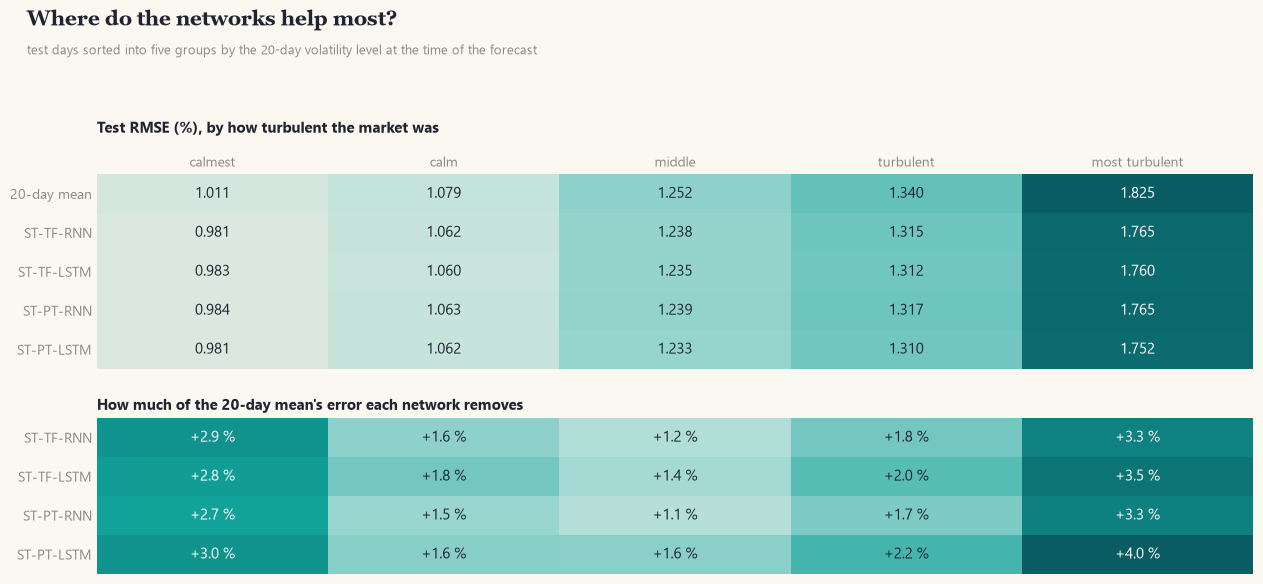

In [20]:
lvl = pd.qcut(A["abs_mean20"][split == 2], 5, labels=["calmest", "calm", "middle", "turbulent", "most turbulent"])
err = pd.DataFrame({k: pd.Series((v["pred"] - yte) ** 2).groupby(lvl).mean() ** 0.5 * 100 for k, v in RUNS.items()})
err["20-day mean"] = pd.Series((A["abs_mean20"][split == 2] - yte) ** 2).groupby(lvl).mean() ** 0.5 * 100
display(err.round(4))
gain = (1 - err[list(RUNS)].div(err["20-day mean"], axis=0)) * 100              # % of the baseline's RMSE that the network removes
fig = plt.figure(figsize=(12.5, 6.4)); gs = fig.add_gridspec(2, 1, height_ratios=[5, 4], hspace=0.28)
a = fig.add_subplot(gs[0]); cols_ = ["20-day mean"] + list(RUNS); Mx = err[cols_].T.values
a.imshow(Mx, cmap=SEQ, aspect="auto", vmin=Mx.min() - 0.1, vmax=Mx.max())
for (i, j), v in np.ndenumerate(Mx): a.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=10.5, color="white" if v > Mx.min() + 0.6 * (Mx.max() - Mx.min()) else C["ink"])
a.set_yticks(range(len(cols_)), cols_); a.set_xticks(range(len(err)), err.index); a.xaxis.tick_top(); a.set_title("Test RMSE (%), by how turbulent the market was", pad=30)
b = fig.add_subplot(gs[1]); Gx = gain.T.values
b.imshow(Gx, cmap=SEQ, aspect="auto", vmin=0, vmax=Gx.max())
for (i, j), v in np.ndenumerate(Gx): b.text(j, i, f"{v:+.1f} %", ha="center", va="center", fontsize=10.5, color="white" if v > 0.6 * Gx.max() else C["ink"])
b.set_yticks(range(len(RUNS)), list(RUNS)); b.set_xticks([]); b.set_title("How much of the 20-day mean's error each network removes")
headline(fig, "Where do the networks help most?", "test days sorted into five groups by the 20-day volatility level at the time of the forecast")
finish(fig, "ST_by_regime", top_in=1.7)

**Reading the regime tables.** Errors grow steeply with the volatility level, as they must: the RMSE is about 1.0 % in the calmest group and 1.8 % in the most turbulent one, simply because the moves to be forecast are bigger. The gain of the networks over the 20-day mean grows in the same direction, from about 3 % of its error in the calmest group (and about 1–2 % in the three middle groups) to 3.3 % for the Keras RNN and 3.5–4.0 % for the LSTMs in the most turbulent group. So the networks help most when markets are stormy, and the LSTMs help a little more than the RNNs there (4.0 % for the PyTorch LSTM against 3.3 % for the Keras RNN), the one place where the longer memory shows. The differences between the models are nevertheless a few tenths of a percent of RMSE, which is small compared with the run-to-run noise we saw in the learning curves.

## 8. Conclusion

**What we did.** We turned 15 years of daily prices of 145 S&P 500 stocks into 537,515 windows of 60 days × 4 features, chose the *size* of the next day's move as the target (the direction of a stock is, as measured here, unpredictable), and trained four networks of identical shape, a 5-layer RNN and a 5-layer LSTM in Keras and in PyTorch, on a chronological split.

**What we found.**

1. **Volatility has a long memory, direction has none.** The autocorrelation of $\lvert r\rvert$ is 0.215 at lag 1 and still 0.048 at lag 60, while the autocorrelation of $r$ stays within the noise band. This is what makes the task learnable at all.
2. **All four networks beat the baselines, with a small margin.** RMSE falls from 1.333 % (20-day mean) to about 1.30 % and the out-of-sample $R^2$ rises from 0.044 to 0.087–0.097. A recurrent network therefore extracts more than a moving average, but day-to-day volatility remains mostly unpredictable: even the best model removes only about 10 % of the squared error.
3. **The LSTM is only marginally better than the RNN.** It is ahead on RMSE, R² and correlation in both libraries (R² 0.092 against 0.088 and 0.097 against 0.087), most visibly in the most turbulent group of days, but the gaps are within the run-to-run noise suggested by the wobbling validation curves, and the two networks are not consistently ordered on MAE. The reason fits the data: the memory of volatility fades within a few weeks and most of the information sits in the last days, which a plain RNN can reach perfectly well; the LSTM's ability to carry information across very long distances is not needed.
4. **The LSTM costs four times the parameters** (38,049 against 9,537) and 1.5–2.7 times the time per epoch, for this marginal gain.
5. **The validation period is a different market** (mean daily move 1.45 % against 1.24 % in training), so validation losses are higher than training losses from epoch 1 and early stopping selects epochs 1 to 4 fairly arbitrarily.

**When is the LSTM worth it?** Here, hardly: for a task whose useful memory is a few weeks long, a plain RNN with a quarter of the parameters is nearly as good. The LSTM's advantage should appear on tasks where evidence must be carried over long distances, such as the longer reviews of the EC notebook.

**Limitations.** One run per configuration (no confidence intervals); survivorship bias in the choice of stocks; a regime shift between the periods; four hand-chosen features and no market-wide or macroeconomic inputs; no hyperparameter search per model; and CPU timings on one machine.

**What to try next.** A longer window (the memory of volatility is still 0.05 at 60 days), a GRU or a bidirectional model for comparison, adding market-wide volatility as an input, forecasting several days ahead (where memory should matter more), several seeds per configuration, and a loss that fits the heavy tails better than the squared error. The numbers quoted above come from the run recorded in §7.